# [실습] 머신러닝이란 무엇인가 — 첫 모델 만들기

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

# Chapter 1 실습. 해지 고객을 미리 찾을 수 있을까?

**필수 머신러닝 · Chapter 1**

| Part | 주제 |
| --- | --- |
| Part 1 | 데이터와 친해지기 |
| Part 2 | 현행 방법 만들기: 사람이 쓰는 규칙 |
| Part 3 | 모델 만들기와 실험 기록 |
| Part 4 | 비교하고 결정하기 |

## 분석 의뢰서

> **의뢰 부서**: 통신사 고객관리(CS)팀
> **목적**: 해지할 가능성이 높은 고객에게 미리 연락해 혜택을 제안하고 싶다.
> **제약**: 상담 인력이 한정되어 있어 모든 고객에게 연락할 수는 없다.
> **질문**: 해지할 고객을 미리 알 수 있을까?

## 오늘 실습의 질문

> **머신러닝 모델은 CS팀이 지금 쓰는 방법보다 얼마나 더 나은가? 그 차이는 모델을 도입할 만한 크기인가?**

이 질문에 답하려면 "지금 쓰는 방법"이 필요합니다. 그래서 여러분이 CS팀 담당자가 되어 **사람이 쓰는 규칙**을 먼저 만들고, 그 규칙과 모델을 **같은 평가용 데이터**에서 겨루게 합니다. 마지막에는 CS팀에 보낼 권고 메모를 씁니다.

## 이 노트북을 쓰는 법

| 표시 | 뜻 |
| --- | --- |
| **[직접 작성]** | 빈 코드 셀을 직접 채웁니다. 강의 교안의 코드를 보지 않고 먼저 써 보세요 |
| **[판단]** | 코드가 아니라 생각을 적는 칸입니다. 셀을 더블클릭해 `나의 답:` 뒤에 적으세요 |
| **[제공]** | 미리 채워 둔 코드입니다. 읽고 실행하세요 |
| **힌트** | 막혔을 때만 펼치세요 |

이 실습의 목표는 정확도를 높이는 것이 아니라 **모델의 점수를 무엇과 비교해 읽을지 스스로 정하는 것**입니다. 판단 칸을 비워 두면 실습이 끝난 것이 아닙니다.

## 준비

`WA_Fn-UseC_-Telco-Customer-Churn.csv` 파일을 이 노트북과 같은 폴더에 두세요.

In [42]:
# [제공] 이 실습에서 쓰는 라이브러리
import platform
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

# 그래프의 한글 글꼴 (환경에 맞는 글꼴이 없으면 글자가 깨질 수 있습니다)
if platform.system() == "Windows":
    plt.rcParams["font.family"] = "Malgun Gothic"
elif platform.system() == "Darwin":
    plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

---
# Part 1. 데이터와 친해지기

강의에서는 피처 세 개만 썼습니다. 여기서는 데이터 전체를 직접 살펴보고, 강의에서 일부러 뺐던 **누적 요금(TotalCharges)** 문제를 직접 해결합니다.

## 1-1. 데이터 불러오기

**[직접 작성]** 데이터를 불러와 `df`에 저장하고, 행과 열의 수, 그리고 처음 5행을 확인하세요.

<details><summary>힌트</summary>

`pd.read_csv("파일 이름")`, `df.shape`, `df.head()`를 차례로 쓰면 됩니다.
</details>

In [43]:
import pandas as pd

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

print(df.shape)   # (행 수, 열 수)
df.head()         # 처음 5행

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1-2. 해지 비율 확인하기

**[직접 작성]** 해지 여부(`Churn`)별 고객 수와 비율을 확인하세요. 강의 Part 2에서 본 숫자와 같은지 확인합니다.

<details><summary>힌트</summary>

`df["Churn"].value_counts()`는 개수를, `value_counts(normalize=True)`는 비율을 보여줍니다.
</details>

In [44]:
# 개수
print(df["Churn"].value_counts())

# 비율
print(df["Churn"].value_counts(normalize=True))

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64


## 1-3. 열의 자료형 확인하기

**[직접 작성]** 각 열의 자료형을 확인하세요.

<details><summary>힌트</summary>

`df.info()` 또는 `df.dtypes`를 쓰세요.
</details>

In [45]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

> **[판단]** 월 요금(`MonthlyCharges`)과 누적 요금(`TotalCharges`)은 둘 다 금액입니다. 그런데 두 열의 자료형이 같은가요? 다르다면 무엇이 다른가요?
>
> 나의 답: 다르다. 월요금은 float64(실수)이고, 누적 요금은 문자열이다. 둘 다 금액이 숫자여야 하는데, 누적 요금이 문자열로 읽혀서 계산에 바로 쓸 수 없다.

## 1-4. 누적 요금이 숫자가 아닌 이유 찾기

누적 요금 열에는 숫자로 바꿀 수 없는 값이 섞여 있습니다. `pd.to_numeric(열, errors="coerce")`는 열을 숫자로 바꾸되, 바꿀 수 없는 값은 빈 값(`NaN`)으로 만들어 줍니다.

**[직접 작성]** 아래 순서로 코드를 작성하세요.

1. 누적 요금을 숫자로 바꾼 결과를 `tc`에 저장한다
2. `tc`에서 빈 값이 몇 개인지 센다
3. 빈 값인 고객들의 `tenure`, `MonthlyCharges`, `TotalCharges`, `Churn`을 출력한다

<details><summary>힌트</summary>

빈 값 개수는 `tc.isna().sum()`, 빈 값인 행만 고르려면 `df[tc.isna()]` 또는 `df.loc[tc.isna(), [열 이름들]]`을 쓰세요.
</details>

In [46]:
# 1. 누적 요금을 숫자로 바꾸기 (바꿀 수 없는 값은 NaN으로)
tc = pd.to_numeric(df["TotalCharges"], errors="coerce")

# 2. 빈 값 개수 세기
print(tc.isna().sum())

# 3. 빈 값인 고객들의 정보 보기
df.loc[tc.isna(), ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

11


,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,,No
753,0,20.25,,No
936,0,80.85,,No
1082,0,25.75,,No
1340,0,56.05,,No
3331,0,19.85,,No
3826,0,25.35,,No
4380,0,20.00,,No
5218,0,19.70,,No
6670,0,73.35,,No


> **[판단]** 빈 값인 고객들에게는 어떤 공통점이 있나요? 이 고객들의 누적 요금이 비어 있는 이유를 추측해 보세요.
>
> 나의 답: 가입 개월 수가 0임. 신규가입이라 아직 요금이 청구되지 않아 누적 요금이 0원으로 보임

## 1-5. 빈 값 처리 방법 정하기

빈 값을 처리하는 방법은 여러 가지입니다.

| 방법 | 코드 예시 | 생각해 볼 점 |
| --- | --- | --- |
| 해당 고객 삭제 | `df = df[tc.notna()]` | 고객을 데이터에서 지워도 되는가? |
| 0으로 채우기 | `tc.fillna(0)` | 이 고객들의 실제 누적 요금은 0인가? |
| 월 요금으로 채우기 | `tc.fillna(df["MonthlyCharges"])` | 첫 달 요금이 이미 청구되었다고 볼 수 있는가? |

정답은 없습니다. 1-4에서 추측한 이유에 가장 잘 맞는 방법을 고르세요. (이 세 방법은 데이터 전체의 통계값을 쓰지 않으므로, 평가용 데이터를 나누기 전에 적용해도 괜찮습니다.)

**[직접 작성]** 고른 방법으로 `df["TotalCharges"]`를 숫자형 열로 바꾸고, 빈 값이 남지 않았는지 확인하세요.

In [47]:
df["TotalCharges"] = tc.fillna(0)

# 확인
print(df["TotalCharges"].dtype)       # float64 나오면 숫자형
print(df["TotalCharges"].isna().sum()) # 0 나오면 빈 값 없음

float64
0


> **[판단]** 어떤 방법을 골랐나요? 그 이유를 한 줄로 적으세요. 이 결정을 CS팀에 보고할 때 알려야 할 점이 있다면 함께 적으세요.
>
> 나의 답: 0으로 채우기로 한다. 실제로 존재하는 고객이기 때문에 삭제는 하지 않는 쪽으로 가고, 월 요금으로 채우기에는 다른 데이터 및 고객들과의 규칙이 어긋남

## 1-6. 평가용 데이터 먼저 떼어 두기

강의 Part 2에서 배운 원칙입니다. **평가용 데이터는 모델이 학습하는 동안 보면 안 됩니다.** 이 실습에서는 규칙을 만들 때도 같은 원칙을 지킵니다. 그래서 데이터를 탐색하기 **전에** 평가용 20%를 먼저 떼어 둡니다. 이후의 탐색과 규칙 만들기는 학습용 데이터(`train_df`)만 보고 하고, 평가용 데이터(`test_df`)는 마지막 채점에만 씁니다.

**[직접 작성]** `df`를 학습용 80%와 평가용 20%로 나눠 `train_df`, `test_df`에 저장하세요. `random_state=42`, `stratify`는 해지 여부(`Churn`)로 합니다.

<details><summary>힌트</summary>

강의 3-2의 ③과 같습니다. 다만 이번에는 `X`, `y`가 아니라 `df` 전체를 나눕니다.

`train_df, test_df = train_test_split(df, test_size=..., random_state=..., stratify=...)`
</details>

In [48]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    df,
    test_size=0.2,          # 평가용 20%
    random_state=42,        # 매번 같은 방식으로 나누기
    stratify=df["Churn"]    # 해지 비율을 양쪽에 똑같이 맞추기
)

# 확인
print(train_df.shape, test_df.shape)
print(train_df["Churn"].value_counts(normalize=True))
print(test_df["Churn"].value_counts(normalize=True))

(5634, 21) (1409, 21)
Churn
No     0.734647
Yes    0.265353
Name: proportion, dtype: float64
Churn
No     0.734564
Yes    0.265436
Name: proportion, dtype: float64


> **[판단]** 데이터를 탐색하기 전에 평가용 데이터를 먼저 떼어 두는 이유는 무엇인가요? 만약 평가용 데이터까지 보면서 규칙을 고친다면 어떤 문제가 생길까요?
>
> 나의 답: 평가용 데이터는 새 고객에게 얼마나 잘 맞는지 확인하는 용도이기 때문에, 평가용 데이터를 보고 수정을 하게 되면 새 고객에게 적용했을 때 성능이 떨어짐. 신뢰할 수 없게 된다

### 체크포인트

여기까지 막혀서 다음으로 넘어가지 못했다면 **아래 셀만 실행**하세요. 1-5에서 빈 값을 0으로 채우는 한 가지 선택을 적용한 것이며, 정답이라는 뜻은 아닙니다. 1-6까지 끝낸 사람은 실행하지 않아도 됩니다.

In [49]:
# [제공] 체크포인트: 1-6까지 끝낸 사람은 실행하지 않아도 됩니다
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df["Churn"])
print(len(train_df), len(test_df))

5634 1409


### 실습 도구 (실행만 하세요)

아래 셀은 이후 Part에서 쓰는 도구를 만듭니다. 읽어 보고 실행하세요.

| 도구 | 하는 일 |
| --- | --- |
| `churn_rate_by(열 이름)` | 학습용 데이터에서 그 열의 값별 해지율을 계산한다 (숫자 열은 `bins`로 구간을 나눈다) |
| `evaluate(이름, 예측)` | 평가용 데이터에서 정확도와, 해지 고객을 몇 명 찾았는지 보여 준다 |
| `make_data(피처 목록)` | 피처 목록으로 학습용·평가용 `X`, `y`를 만든다 |
| `record(...)` | 실험 결과를 기록표에 한 줄 추가한다 |

In [50]:
# [제공] 실습 도구
y_test = test_df["Churn"]

def churn_rate_by(col, bins=None):
    """학습용 데이터에서 col의 값별 해지율을 계산합니다. 숫자 열은 bins로 구간을 나눕니다."""
    key = pd.cut(train_df[col], bins) if bins is not None else train_df[col]
    return train_df.groupby(key, observed=True)["Churn"].apply(lambda s: (s == "Yes").mean()).round(3)

def evaluate(name, pred):
    """평가용 데이터에서 예측(Yes/No)을 채점합니다. 정확도를 돌려줍니다."""
    pred = pd.Series(np.asarray(pred), index=test_df.index)
    acc = (pred == y_test).mean()
    flagged = (pred == "Yes").sum()
    found = ((pred == "Yes") & (y_test == "Yes")).sum()
    total = (y_test == "Yes").sum()
    print(f"[{name}] 정확도 {acc:.3f} | 해지로 예측 {flagged}명 중 실제 해지 {found}명 | 전체 해지 고객 {total}명 중 {found}명을 찾음")
    return acc

def make_data(features):
    """피처 목록을 받아 학습용·평가용 X, y를 만듭니다. 평가용 고객은 항상 같습니다."""
    X = pd.get_dummies(df[features])
    return X.loc[train_df.index], X.loc[test_df.index], train_df["Churn"], test_df["Churn"]

experiment_log = []
def record(name, features, depth, accuracy):
    """실험 결과를 기록표에 한 줄 추가합니다."""
    experiment_log.append({
        "실험": name,
        "피처": ", ".join(features) if features else "-",
        "깊이": depth,
        "평가용 정확도": round(float(accuracy), 3),
    })
    print(f"기록: [{name}] {accuracy:.3f}")

## 1-7. 해지와 관련 있어 보이는 정보 찾기

이제 학습용 데이터에서 "어떤 고객이 많이 해지하는가"를 찾아봅니다. 이 관찰이 Part 2에서 규칙의 재료가 됩니다.

전체 평균 해지율은 약 26.5%입니다. 이보다 **눈에 띄게 높은** 집단을 찾는 것이 목표입니다.

**[직접 작성]** `churn_rate_by`로 계약 유형(`Contract`)별 해지율을 확인하세요.

In [51]:
churn_rate_by("Contract")*100

Contract
Month-to-month    42.7
One year          11.1
Two year           2.9
Name: Churn, dtype: float64

**[직접 작성]** 다른 열도 같은 방법으로 살펴보세요. **세 개 이상**의 열을 골라 해지율을 확인합니다. 숫자 열(`tenure`)은 구간을 나눠야 합니다.

<details><summary>힌트</summary>

열 이름 목록은 `df.columns.tolist()`로 볼 수 있습니다. 한 줄에 하나씩 `print(churn_rate_by("열 이름"))`을 쓰세요.

가입 기간처럼 숫자 열은 구간 경계를 함께 줍니다.

`churn_rate_by("tenure", bins=[-1, 6, 12, 24, 48, 72])`
</details>

In [52]:
# 여기에 코드를 작성하세요

def show_churn(col, bins=None, title=None):
    rate = churn_rate_by(col, bins)
    table = rate.sort_values(ascending=False).to_frame("해지율")
    table["해지율"] = table["해지율"].map("{:.1%}".format)
    if title:
        table.index.name = title   # 표 왼쪽 위 이름 바꾸기
    return table

display(show_churn("tenure", bins=[-1, 6, 12, 24, 48, 72], title="가입 기간"))
display(show_churn("InternetService", title="인터넷 서비스"))
display(show_churn("PaymentMethod", title="결제 방법"))
display(show_churn("TechSupport", title="기술 지원"))

,해지율
가입 기간,
"(-1, 6]",52.2%
"(6, 12]",37.2%
"(12, 24]",28.6%
"(24, 48]",20.2%
"(48, 72]",9.9%


,해지율
인터넷 서비스,
Fiber optic,42.1%
DSL,18.7%
No,7.2%


,해지율
결제 방법,
Electronic check,45.7%
Mailed check,19.3%
Bank transfer (automatic),16.2%
Credit card (automatic),14.9%


,해지율
기술 지원,
No,41.8%
Yes,15.2%
No internet service,7.2%


**[제공]** 해지 여부에 따라 가입 기간(`tenure`) 분포가 어떻게 다른지 그려 봅니다.

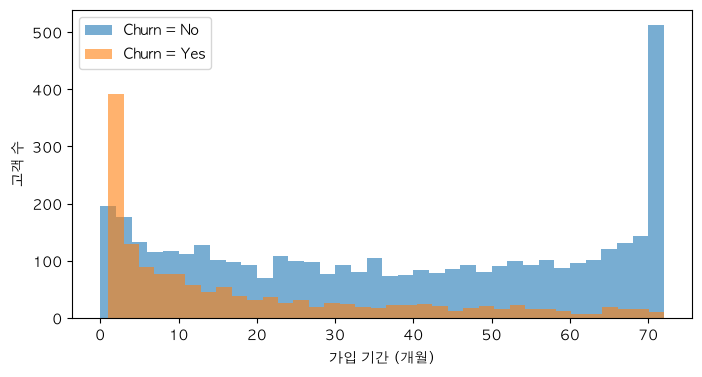

In [53]:
# [제공] 해지 여부별 가입 기간 분포 (학습용 데이터)
fig, ax = plt.subplots(figsize=(8, 4))
for label in ["No", "Yes"]:
    ax.hist(train_df.loc[train_df["Churn"] == label, "tenure"], bins=36, alpha=0.6, label=f"Churn = {label}")
ax.set_xlabel("가입 기간 (개월)")
ax.set_ylabel("고객 수")
ax.legend()
plt.show()

> **[판단]** 해지율이 전체 평균보다 눈에 띄게 높은 집단을 두 개 이상 적어 보세요. (예: "○○인 고객은 해지율이 △△%")
>
> 나의 답:  
> 가입 기간 6개월 이하 고객은 해지율이 52.2%    
> 월 단위 계약 고객은 해지율이 42.7%    

> **[판단]** 이 집계만 보고 "그 조건을 바꾸게 하면 해지가 줄어든다"고 말할 수 있을까요? 강의 3-4의 세 번째 항목을 떠올려 보세요.
>
> 나의 답: 말할 수 없다. 약정을 걸면 할인을 받는데도 월 단위를 골랐다는 건, 고객이 처음부터 오래 쓸 생각이 없었을 수 있다는 뜻이다. 즉 해지할 마음이 있는 고객이 월 단위를 고른 것일 수 있으므로, 계약 유형을 바꾸게 해도 해지가 줄어든다는 보장은 없다.

---
# Part 2. 현행 방법 만들기: 사람이 쓰는 규칙

여러분이 CS팀 담당자라고 생각해 보세요. 머신러닝 없이, 오늘 전화할 고객을 고르는 **규칙 하나**를 만들어 봅시다. 강의 2-4에서 본 세 번째 베이스라인, "현행 규칙"입니다.

## 규칙을 만들 때의 약속

- 조건은 **두세 개를 넘기지 않습니다.** 현업에서 실제로 쓸 수 있을 만큼 단순해야 합니다.
- 근거는 **1-7에서 본 집계**입니다. 평가용 데이터를 보고 규칙을 고치지 않습니다.
- 규칙은 "이 조건에 맞는 고객은 해지 위험(Yes), 아니면 No"로 답합니다.

## 2-1. 베이스라인 계산

먼저 비교 기준을 만듭니다. 모든 고객에게 "No"라고 답하는 방법의 성적입니다.

**[직접 작성]** 평가용 고객 전원에게 "No"라고 답하는 예측을 만들어 `evaluate`로 채점하고, 정확도를 `baseline_acc`에 저장하세요.

<details><summary>힌트</summary>

`baseline_pred = pd.Series("No", index=test_df.index)`로 예측을 만들고, `baseline_acc = evaluate("전부 No", baseline_pred)`로 채점합니다.
</details>

In [54]:
# 평가용 고객 전원에게 "No"라고 답하는 예측 만들기
baseline_pred = pd.Series("No", index=test_df.index)

# 채점하고 정확도 저장하기
baseline_acc = evaluate("전부 No", baseline_pred)

[전부 No] 정확도 0.735 | 해지로 예측 0명 중 실제 해지 0명 | 전체 해지 고객 374명 중 0명을 찾음


## 2-2. 나의 규칙 만들기

먼저 말로 적고, 그다음 코드로 옮깁니다.

> **[판단]** 나의 규칙(말로): 만약 ______ 이면 해지 위험으로 본다.
>
> 이 조건을 고른 근거(1-7의 어떤 집계인가):
>
> 나의 답: 월 단위 계약이면서 가입 6개월 이하면 해지 위험으로 본다. 근거는 1-7에서 가입 6개월 이하 해지율 52.2%, 월 단위 계약 해지율 42.7%로 둘 다 평균 26.5%보다 높았음

**[직접 작성]** 규칙을 코드로 옮겨 평가용 고객에게 적용하고, 예측을 `rule_pred`에 저장하세요. 그다음 `evaluate`로 채점해 정확도를 `rule_acc`에 저장합니다.

<details><summary>힌트</summary>

조건은 `&`(그리고), `|`(또는)로 묶고, 조건마다 괄호를 칩니다. 예를 들어 "인터넷이 광케이블이고 월 요금이 80 이상"이라면

```python
condition = (test_df["InternetService"] == "Fiber optic") & (test_df["MonthlyCharges"] >= 80)
rule_pred = pd.Series(np.where(condition, "Yes", "No"), index=test_df.index)
rule_acc = evaluate("내 규칙", rule_pred)
```

이 예시는 형식만 보여주는 것입니다. 여러분의 규칙을 쓰세요.
</details>

In [55]:
# 나의 규칙: 월 단위 계약이면서 가입 6개월 이하면 해지 위험(Yes)
condition = (test_df["Contract"] == "Month-to-month") & (test_df["tenure"] <= 6)
rule_pred = pd.Series(np.where(condition, "Yes", "No"), index=test_df.index)
rule_acc = evaluate("내 규칙", rule_pred)

[내 규칙] 정확도 0.769 | 해지로 예측 291명 중 실제 해지 170명 | 전체 해지 고객 374명 중 170명을 찾음


> **[판단]** 내 규칙은 "전부 No"보다 정확도가 높은가요? 두 방법이 찾아낸 해지 고객 수도 비교해 보세요.
>
> 나의 답: 높다. 정확도 0.769로 전부 No(0.735)보다 3.4%p 높고, 해지 고객도 374명 중 0명 → 170명을 찾음

> **[판단]** 정확도는 비슷한데 찾아낸 해지 고객 수가 크게 다른 두 방법이 있다면, CS팀에는 어느 쪽이 더 쓸모 있을까요? 이유를 적어 보세요.
>
> 나의 답: 해지 고객을 더 많이 찾는 쪽. CS팀 목적은 떠날 고객에게 미리 연락하는 거라 정확도가 같아도 찾아낸 해지 고객 수가 실제 가치임

---
# Part 3. 모델 만들기와 실험 기록

이제 모델을 만들어 내 규칙과 겨룹니다. 강의 Part 3의 코드를 보지 말고 먼저 직접 써 보세요. 막히면 강의 3-2를 참고해도 됩니다.

## 3-1. 첫 모델 만들기

**[직접 작성]** 아래 순서로 작성하세요.

1. `make_data(["tenure", "MonthlyCharges", "Contract"])`로 `X_train, X_test, y_train, y_test`를 만든다
2. 깊이 2 결정트리(`max_depth=2`, `random_state=42`)를 학습한다
3. 평가용 데이터의 예측을 `evaluate`로 채점해 정확도를 `tree_acc`에 저장한다

<details><summary>힌트</summary>

강의 3-2의 ⑤와 같은 순서입니다. 채점은 `tree_acc = evaluate("트리(깊이 2)", model.predict(X_test))`로 합니다.
</details>

In [56]:
# 1. 데이터 만들기
X_train, X_test, y_train, y_test = make_data(["tenure", "MonthlyCharges", "Contract"])

# 2. 깊이 2 결정트리 학습
model = DecisionTreeClassifier(max_depth=2, random_state=42)
model.fit(X_train, y_train)

# 3. 평가용 데이터로 채점
tree_acc = evaluate("트리(깊이 2)", model.predict(X_test))

[트리(깊이 2)] 정확도 0.740 | 해지로 예측 441명 중 실제 해지 224명 | 전체 해지 고객 374명 중 224명을 찾음


## 3-2. 실험 기록표 시작하기

피처와 깊이를 바꿔 가며 여러 번 실험하면, 어떤 조건에서 몇 점이 나왔는지 금방 헷갈립니다. 그래서 실험마다 한 줄씩 기록을 남깁니다. 이 습관은 이후 Chapter에서도 계속 씁니다.

**[직접 작성]** 지금까지의 결과 세 가지(전부 No, 내 규칙, 깊이 2 트리)를 `record`로 기록하세요. 베이스라인과 규칙은 피처에 `[]`, 깊이에 `"-"`를 넣으면 됩니다.

<details><summary>힌트</summary>

`record("실험 이름", 피처 목록, 깊이, 정확도)` 형태입니다.
</details>

In [57]:
record("전부 No", [], "-", baseline_acc)
record("내 규칙", [], "-", rule_acc)
record("트리(깊이 2)", ["tenure", "MonthlyCharges", "Contract"], 2, tree_acc)

기록: [전부 No] 0.735
기록: [내 규칙] 0.769
기록: [트리(깊이 2)] 0.740


## 3-3. 피처와 깊이를 바꿔 보기

**[직접 작성]** 피처를 추가하거나 깊이를 바꿔 가며 **세 번 이상** 실험하세요. 매번 `evaluate`로 채점하고 `record`로 기록합니다.

실험하기 전에, 피처를 고를 때 하나 확인할 것이 있습니다.

> **[판단]** 누적 요금(`TotalCharges`)을 피처로 쓰기 전에 생각해 보세요. 이 값은 "언제 찍힌 사진"일까요? 해지한 고객의 누적 요금은 해지 시점에서 멈춰 있지 않을까요? 이 피처를 쓸지 말지, 이유와 함께 적으세요. (정답은 Chapter 4에서 다시 확인합니다.)
>
> 나의 답: 쓰지 않는다. 해지 고객은 누적 요금이 해지 시점에서 멈춰 있고, 사실상 가입 기간 × 월 요금이라 tenure와 겹치는 정보임

<details><summary>힌트</summary>

한 번의 실험은 다음 네 줄입니다.

```python
features = ["tenure", "MonthlyCharges", "Contract", "InternetService"]
X_tr, X_te, y_tr, y_te = make_data(features)
m = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_tr, y_tr)
acc = evaluate("인터넷 추가, 깊이 3", m.predict(X_te))
record("인터넷 추가, 깊이 3", features, 3, acc)
```

깊이는 2~5 사이에서 바꿔 보세요. 더 깊게 하면 어떻게 되는지는 강의 3-5의 표에서 이미 봤습니다.
</details>

In [58]:
# 실험 1: 피처 그대로, 깊이 3
features = ["tenure", "MonthlyCharges", "Contract"]
X_tr, X_te, y_tr, y_te = make_data(features)
m = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_tr, y_tr)
acc = evaluate("기본 3개, 깊이 3", m.predict(X_te))
record("기본 3개, 깊이 3", features, 3, acc)

# 실험 2: 인터넷 서비스 추가, 깊이 3
features = ["tenure", "MonthlyCharges", "Contract", "InternetService"]
X_tr, X_te, y_tr, y_te = make_data(features)
m = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_tr, y_tr)
acc = evaluate("인터넷 추가, 깊이 3", m.predict(X_te))
record("인터넷 추가, 깊이 3", features, 3, acc)

# 실험 3: 결제 방법·기술 지원까지 추가, 깊이 4
features = ["tenure", "MonthlyCharges", "Contract", "InternetService", "PaymentMethod", "TechSupport"]
X_tr, X_te, y_tr, y_te = make_data(features)
m = DecisionTreeClassifier(max_depth=4, random_state=42).fit(X_tr, y_tr)
acc = evaluate("6개, 깊이 4", m.predict(X_te))
record("6개, 깊이 4", features, 4, acc)

# 실험 4: 같은 6개, 깊이 5
X_tr, X_te, y_tr, y_te = make_data(features)
m = DecisionTreeClassifier(max_depth=5, random_state=42).fit(X_tr, y_tr)
acc = evaluate("6개, 깊이 5", m.predict(X_te))
record("6개, 깊이 5", features, 5, acc)

[기본 3개, 깊이 3] 정확도 0.779 | 해지로 예측 203명 중 실제 해지 133명 | 전체 해지 고객 374명 중 133명을 찾음
기록: [기본 3개, 깊이 3] 0.779


[인터넷 추가, 깊이 3] 정확도 0.782 | 해지로 예측 197명 중 실제 해지 132명 | 전체 해지 고객 374명 중 132명을 찾음
기록: [인터넷 추가, 깊이 3] 0.782
[6개, 깊이 4] 정확도 0.792 | 해지로 예측 257명 중 실제 해지 169명 | 전체 해지 고객 374명 중 169명을 찾음
기록: [6개, 깊이 4] 0.792
[6개, 깊이 5] 정확도 0.794 | 해지로 예측 368명 중 실제 해지 226명 | 전체 해지 고객 374명 중 226명을 찾음
기록: [6개, 깊이 5] 0.794


**[제공]** 실험 기록표를 정확도 순으로 봅니다.

In [59]:
# [제공] 실험 기록표 보기
pd.DataFrame(experiment_log).sort_values("평가용 정확도", ascending=False, kind="stable")

,실험,피처,깊이,평가용 정확도
6,"6개, 깊이 5","tenure, MonthlyCharges, Contract, InternetServ...",5,0.794
5,"6개, 깊이 4","tenure, MonthlyCharges, Contract, InternetServ...",4,0.792
4,"인터넷 추가, 깊이 3","tenure, MonthlyCharges, Contract, InternetService",3,0.782
3,"기본 3개, 깊이 3","tenure, MonthlyCharges, Contract",3,0.779
1,내 규칙,-,-,0.769
2,트리(깊이 2),"tenure, MonthlyCharges, Contract",2,0.740
0,전부 No,-,-,0.735


> **[판단]** 가장 좋은 모델은 "전부 No"보다 몇 %p 나은가요? 내 규칙보다는 몇 %p 나은가요?
>
> 나의 답: 최고 모델(6개, 깊이 5) 0.794로 전부 No보다 5.9%p, 내 규칙(0.769)보다 2.5%p 높다

> **[판단]** 가장 좋은 모델이 해지 고객을 몇 명 찾아냈나요? 내 규칙이 찾아낸 수와 비교해 보세요.
>
> 나의 답: 368명에게 연락해 226명을 찾음. 내 규칙은 291명 중 170명이라 56명 더 찾았지만 연락할 고객도 77명 늘어남

## 3-4. 가장 나은 모델의 규칙 읽기

**[직접 작성]** 기록표에서 가장 나은 실험을 골라 그 모델을 다시 학습하고, `plot_tree`로 그리세요.

<details><summary>힌트</summary>

강의 3-3의 ⑦을 참고하세요. 깊이 3 트리는 글자가 작아지므로 `plt.figure(figsize=(20, 8))`처럼 그림을 크게 하세요.
</details>

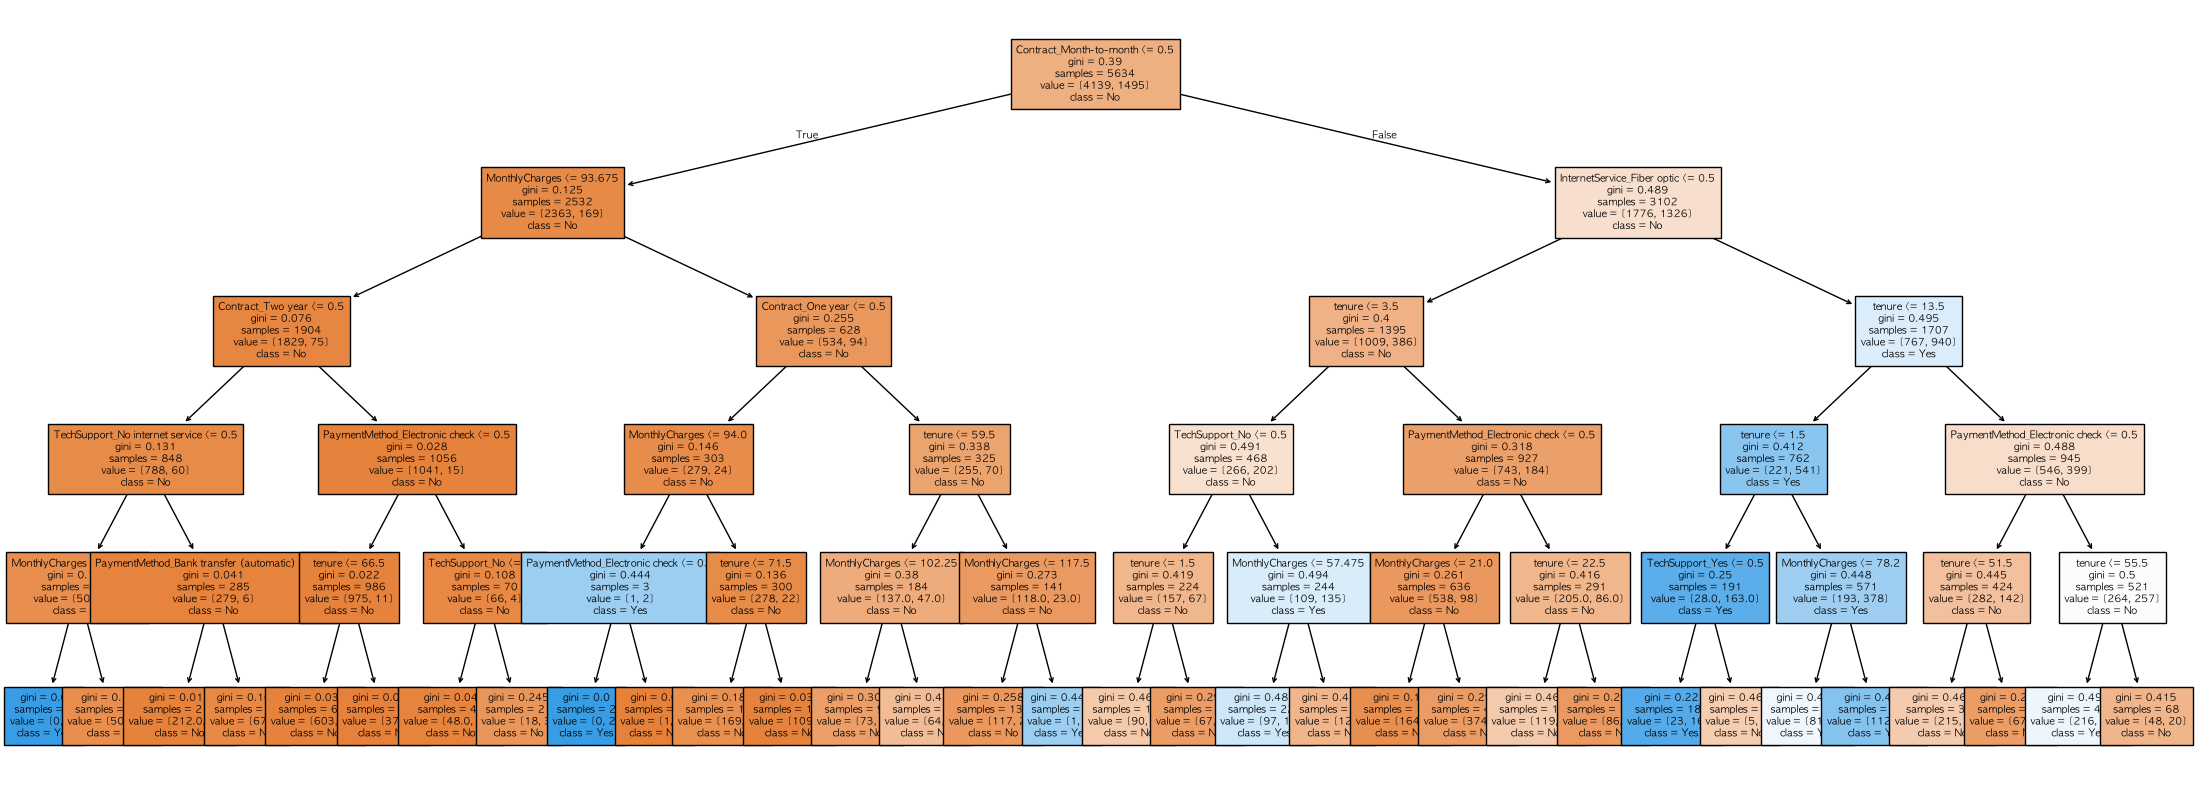

|--- Contract_Month-to-month <= 0.50
|   |--- MonthlyCharges <= 93.67
|   |   |--- Contract_Two year <= 0.50
|   |   |   |--- TechSupport_No internet service <= 0.50
|   |   |   |   |--- MonthlyCharges <= 24.23
|   |   |   |   |   |--- weights: [0.00, 1.00] class: Yes
|   |   |   |   |--- MonthlyCharges >  24.23
|   |   |   |   |   |--- weights: [509.00, 53.00] class: No
|   |   |   |--- TechSupport_No internet service >  0.50
|   |   |   |   |--- PaymentMethod_Bank transfer (automatic) <= 0.50
|   |   |   |   |   |--- weights: [212.00, 2.00] class: No
|   |   |   |   |--- PaymentMethod_Bank transfer (automatic) >  0.50
|   |   |   |   |   |--- weights: [67.00, 4.00] class: No
|   |   |--- Contract_Two year >  0.50
|   |   |   |--- PaymentMethod_Electronic check <= 0.50
|   |   |   |   |--- tenure <= 66.50
|   |   |   |   |   |--- weights: [603.00, 10.00] class: No
|   |   |   |   |--- tenure >  66.50
|   |   |   |   |   |--- weights: [372.00, 1.00] class: No
|   |   |   |--- PaymentMe

In [60]:
# 기록표에서 가장 나은 실험(6개 피처, 깊이 5)을 다시 학습
best_features = ["tenure", "MonthlyCharges", "Contract", "InternetService", "PaymentMethod", "TechSupport"]
X_tr, X_te, y_tr, y_te = make_data(best_features)
best_model = DecisionTreeClassifier(max_depth=5, random_state=42).fit(X_tr, y_tr)

plt.figure(figsize=(28, 10))
plot_tree(best_model, feature_names=X_tr.columns, class_names=best_model.classes_,
          filled=True, fontsize=7)
plt.show()

# 그림이 작아서 글로도 출력
from sklearn.tree import export_text
print(export_text(best_model, feature_names=list(X_tr.columns), show_weights=True))

> **[판단]** "Yes"로 예측하는 잎을 하나 골라, 그 잎에 도착하는 고객의 조건을 말로 풀어 쓰세요. 그 잎의 고객 중 실제 해지 비율은 얼마인가요? (`value`로 계산)
>
> 나의 답: 월 단위 계약 + 광랜 + 가입 1개월 이하 + 기술 지원 미가입 고객. 학습용 183명 중 160명이 해지해 해지 비율 약 87%

---
# Part 4. 비교하고 결정하기

이제 질문으로 돌아옵니다. **모델은 CS팀이 지금 쓰는 방법(내 규칙)보다 얼마나 나은가? 그 차이는 도입할 만한 크기인가?**

## 4-1. 예상 걸기

곧 다른 수강생들의 규칙과 모델 점수를 한 표에서 함께 봅니다. 표를 열기 **전에** 먼저 예상을 적어 두세요. 틀려도 괜찮습니다. 예상이 빗나간 지점이 오늘 가장 많이 배우는 곳입니다.

> **[판단]** 예상 ① 교실 전체에서 "모델이 규칙을 이긴 사람"은 몇 %일까요? (대략의 비율로)
>
> 나의 답: 70% 정도는 모델이 규칙을 이길 것 같다

> **[판단]** 예상 ② 교실에서 가장 높은 규칙 정확도는 어느 정도일까요? 그 규칙은 조건이 많을까요, 적을까요?
>
> 나의 답: 0.77 정도. 조건이 1~2개인 단순한 규칙일 것 같다

## 4-2. 공유용 한 줄 만들기

**[직접 작성]** `my_rule_text`에 나의 규칙을 한 줄로 적으세요. (예: `"월 단위 계약이면서 가입 12개월 이하"`)

In [61]:
my_rule_text = "월 단위 계약이면서 가입 6개월 이하"

**[제공]** 공유 표에 붙여 넣을 한 줄과, 내 실험 기록표를 출력합니다.

In [62]:
# [제공] 공유용 한 줄 + 실험 기록표
log = pd.DataFrame(experiment_log)
models = log[~log["실험"].isin(["전부 No", "내 규칙"])]
best_row = models.sort_values("평가용 정확도", ascending=False, kind="stable").iloc[0]

print("공유 표에 붙여 넣으세요:")
print(f"규칙: {my_rule_text} | 규칙 정확도 {rule_acc:.3f} | 최고 모델 {best_row['실험']} {best_row['평가용 정확도']:.3f}")
print()
log.sort_values("평가용 정확도", ascending=False, kind="stable")

공유 표에 붙여 넣으세요:
규칙: 월 단위 계약이면서 가입 6개월 이하 | 규칙 정확도 0.769 | 최고 모델 6개, 깊이 5 0.794



,실험,피처,깊이,평가용 정확도
6,"6개, 깊이 5","tenure, MonthlyCharges, Contract, InternetServ...",5,0.794
5,"6개, 깊이 4","tenure, MonthlyCharges, Contract, InternetServ...",4,0.792
4,"인터넷 추가, 깊이 3","tenure, MonthlyCharges, Contract, InternetService",3,0.782
3,"기본 3개, 깊이 3","tenure, MonthlyCharges, Contract",3,0.779
1,내 규칙,-,-,0.769
2,트리(깊이 2),"tenure, MonthlyCharges, Contract",2,0.740
0,전부 No,-,-,0.735


## 4-3. 공유 표를 본 뒤

> **[판단]** 예상 ①, ②는 맞았나요? 가장 크게 빗나간 것은 무엇이고, 왜 빗나갔다고 생각하나요?
>
> 나의 답: (공유 표 확인 후 수정) 내 결과로는 모델이 이겼지만 차이가 2.5%p로 생각보다 작았음

> **[판단]** 조건이 적고 단순한 규칙과 조건이 많은 규칙 중, 모델과 더 비슷한 점수를 낸 것은 어느 쪽이었나요?
>
> 나의 답: (공유 표 확인 후 수정) 조건이 적은 단순한 규칙이 모델과 더 비슷했음. 조건이 많으면 해당 고객이 줄어 놓치는 해지 고객이 많아짐

> **[판단]** 모델이 규칙을 몇 %p 이긴다면 CS팀은 모델을 도입해야 할까요? 규칙은 누구나 이해하고 내일부터 쓸 수 있지만 모델은 그렇지 않다는 점도 함께 생각해 보세요.
>
> 나의 답: 2.5%p 차이라면 바로 도입보다 규칙 유지가 낫다. 규칙은 누구나 이해하고 내일부터 쓸 수 있지만, 모델은 운영·설명 비용이 들기 때문

## 4-4. CS팀 권고 메모

분석 결과를 CS팀 팀장에게 메시지로 보낸다고 생각하고 쓰세요. 팀장은 머신러닝 용어를 모릅니다. 아래 네 가지가 모두 들어가야 합니다.

1. **무엇을 예측했는가** (누가, 어떤 정보로, 무엇을)
2. **지금 쓰는 방법(내 규칙)과 비교해 얼마나 나은가** (정확도와, 찾아낸 해지 고객 수 모두)
3. **권고**: 모델 도입 / 규칙 유지 / 보류 중 하나를 고르고, 이유를 쓴다
4. **주의할 점**: 1-5의 빈 값 처리 결정, 타깃 정의의 한계(강의 2-1), 아직 확인하지 못한 것

> **[판단]** CS팀 권고 메모:
>
> 1. 예측한 것: 고객의 계약 유형, 가입 기간, 월 요금, 인터넷 서비스, 결제 방법, 기술 지원 정보로 그 고객이 해지할지(예/아니오)를 예측함
>
> 2. 현행 방법과의 비교: 평가 고객 1,409명 기준, 지금 규칙(월 단위 계약 + 가입 6개월 이하)은 76.9%를 맞히고 해지 고객 374명 중 170명을 찾음. 모델은 79.4%를 맞히고 226명을 찾음. 참고로 "아무도 해지 안 함"이라고만 해도 73.5%를 맞힘
>
> 3. 권고와 이유: 보류. 모델이 해지 고객을 56명 더 찾지만 연락할 고객도 77명 늘고, 맞힌 비율 차이는 2.5%p뿐임. 당분간 규칙을 쓰면서 일부 고객에게 모델을 시범 적용해 비교해 보는 것을 권함
>
> 4. 주의할 점: 누적 요금이 비어 있던 신규 고객 11명은 0원으로 채움. "해지"는 데이터에 기록된 해지 여부라 실제 해지 시점·이유와 다를 수 있음. 연락하면 해지가 실제로 줄어드는지는 아직 확인하지 못함


---
# 마무리

## 이 Chapter의 판단 포인트

> **정확도 74%는 좋은 숫자인가? 베이스라인을 보기 전까지는 알 수 없다.**

## 개인 검증 체크리스트에 추가

오늘 실습에서 내가 실제로 겪은 일을 바탕으로, 체크리스트의 첫 줄을 내 말로 적으세요.

예: "모델 점수를 보면 '전부 No'와 현행 규칙의 점수를 먼저 찾는다."

> **[판단]** 나의 체크리스트 1번:
>
> 나의 답: 모델 점수를 보면 전부 No와 현행 규칙 점수를 먼저 찾고, 정확도와 함께 찾아낸 해지 고객 수도 같이 본다

## 제출물

- 이 노트북 (모든 **[판단]** 칸을 채운 상태)
- 4-2에서 만든 공유용 한 줄

수고했습니다. 다음 Chapter 2에서는 숫자를 예측하는 **회귀**를 배웁니다.